# Retail & E-commerce — Data Cleaning, Transformation & Testing Pipeline

Walk-through notebook for the `retail_pipeline` package (`src/retail_pipeline/`). The pipeline code lives in importable modules; this notebook only *runs* it on the demo data and shows the results. See `docs/MODULE_GUIDE.md` for what lives where.

**Run after** `pip install -e ".[dev]"`. Run everything top to bottom with **Run All**.

## Setup

In [34]:
import os, sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").is_dir():            # notebook opened from notebooks/
    REPO_ROOT = REPO_ROOT.parent
for p in (REPO_ROOT, REPO_ROOT / "scripts"):    # `tests` and `scripts` are importable from the notebook
    if str(p) not in sys.path: sys.path.insert(0, str(p))

import numpy as np
import pandas as pd
from src.retail_pipeline import *                   # public API: run_pipeline, clean_returns, dq_report, transforms, ...
from src.retail_pipeline.config import OUTPUT_DIR
from tests.helpers import expected_view         # projects the standardised table onto the brief's layout

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 70); pd.set_option("display.max_colwidth", 60)
OUTPUT_DIR = str(REPO_ROOT / OUTPUT_DIR)

## 1. Run on the brief's sample
The exact 4 rows from the brief, compared with the brief's *Expected Cleaned & Standardized Dataset* (test `B16` asserts the match).

In [35]:
sample_res = run_pipeline(SAMPLE_RAW)
expected_view(sample_res.standardized[sample_res.standardized.Is_Authoritative])

,Order_ID,Customer_ID,Order_TS_UTC,SKU,Product,Qty,Unit_Price,Discount,Currency,Status
0,ORD-1042,CUST-007,2026-05-14T14:30:00Z,MUG-BLK,Black Ceramic Mug,2,450.0,45.0,INR,DELIVERED
1,ORD-1043,CUST-008,REVIEW: ambiguous local time,TSHIRT-M,Cotton Tee M,-1,799.0,0.0,INR,RETURN_REVIEW
2,ORD-1044,CUST-009,2026-05-15T05:30:00Z,BAG-01,Canvas Tote,1,18.0,0.0,USD,SHIPPED


In [36]:
# Row-level decisions: disposition + blocking reasons + warnings
sample_res.standardized[["Raw_Row_ID", "Order_ID", "Disposition", "Review_Reasons", "Warnings", "Duplicate_Of", "Revenue_Class"]]

,Raw_Row_ID,Order_ID,Disposition,Review_Reasons,Warnings,Duplicate_Of,Revenue_Class
0,1,ORD-1042,CLEAN,,,None,FULFILLED
1,2,ORD-1042,SUPERSEDED_DUPLICATE,,,1,FULFILLED
2,3,ORD-1043,REVIEW,"INVALID_QTY, RETURN_ON_ORDER_LINE, TS_AMBIGUOUS_NO_TZ",,None,REVIEW
3,4,ORD-1044,CLEAN,,FX_UNAVAILABLE,None,IN_PIPELINE


## 2. Run on the full demo set (sample + extended rows)
`fx_rates` is intentionally empty: with no documented FX rate USD stays unconverted (TC07). Load real rates with `load_fx_rates('fx.csv')`.

In [37]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
fx_rates = {}
res = run_pipeline(ALL_RAW, fx_rates=fx_rates)
print("Disposition counts:\n", res.standardized.Disposition.value_counts().to_string(), "\n")
print("Exception counts by flag:\n", res.exceptions.groupby(["Severity", "Flag"]).size().to_string())

Disposition counts:
 Disposition
CLEAN                   12
REVIEW                   3
SUPERSEDED_DUPLICATE     3 

Exception counts by flag:
 Severity  Flag                 
BLOCKING  CONFLICTING_DUPLICATE    1
          INVALID_QTY              1
          RETURN_ON_ORDER_LINE     1
          SKU_UNKNOWN              1
          TS_AMBIGUOUS_NO_TZ       1
WARNING   CUSTOMER_UNMATCHED       1
          DISCOUNT_UNKNOWN         1
          FX_UNAVAILABLE           2


In [38]:
# Cleaned dataset (usable for metrics) - money columns are integer minor units (paise)
res.clean[["Raw_Row_ID", "Order_ID", "Customer_ID", "Order_TS_UTC", "SKU", "Product", "Qty", "Currency", "Status", "Gross_Minor", "Net_Minor", "Warnings"]]

,Raw_Row_ID,Order_ID,Customer_ID,Order_TS_UTC,SKU,Product,Qty,Currency,Status,Gross_Minor,Net_Minor,Warnings
0,1,ORD-1042,CUST-007,2026-05-14T14:30:00Z,MUG-BLK,Black Ceramic Mug,2,INR,DELIVERED,90000,81000,
1,4,ORD-1044,CUST-009,2026-05-15T05:30:00Z,BAG-01,Canvas Tote,1,USD,SHIPPED,1800,1800,FX_UNAVAILABLE
2,5,ORD-2001,CUST-010,2026-05-16T03:30:00Z,HOODIE-L,Hoodie L,1,INR,DELIVERED,149900,142405,
3,6,ORD-2001,CUST-010,2026-05-16T03:30:00Z,BTL-STL,Steel Bottle,2,INR,DELIVERED,130000,130000,
4,7,ORD-2002,CUST-011,2026-05-17T02:30:00Z,MUG-BLK,Black Ceramic Mug,3,INR,DELIVERED,135000,121500,
5,8,ORD-2003,CUST-012,2026-05-17T10:00:00Z,TSHIRT-M,Cotton Tee M,2,INR,DELIVERED,159800,159800,
6,9,ORD-2004,CUST-008,2026-05-18T12:00:00Z,NOTE-A5,Spiral Notebook A5,3,INR,DELIVERED,12000,12000,
7,10,ORD-2005,CUST-009,2026-05-18T12:30:00Z,MUG-BLK,Black Ceramic Mug,1,INR,CANCELLED,45000,45000,
8,11,ORD-2006,NaN,2026-05-19T08:00:00Z,BAG-01,Canvas Tote,2,USD,DELIVERED,3600,3600,"CUSTOMER_UNMATCHED, FX_UNAVAILABLE"
9,13,ORD-2008,CUST-011,2026-05-20T09:00:00Z,HOODIE-L,Hoodie L,1,INR,DELIVERED,149900,<NA>,DISCOUNT_UNKNOWN


In [39]:
# Review / quarantine dataset (blocking flags -> excluded from every metric)
res.review[["Raw_Row_ID", "Order_ID", "SKU", "Qty", "Review_Reasons"]]

,Raw_Row_ID,Order_ID,SKU,Qty,Review_Reasons
0,3,ORD-1043,TSHIRT-M,-1,"INVALID_QTY, RETURN_ON_ORDER_LINE, TS_AMBIGUOUS_NO_TZ"
1,12,ORD-2007,NaN,1,SKU_UNKNOWN
2,17,ORD-2011,BTL-STL,1,CONFLICTING_DUPLICATE


In [40]:
# Exception queue and superseded duplicates
display(res.exceptions)
res.superseded[["Raw_Row_ID", "Order_ID", "Duplicate_Of", "Event_Version"]]

,Raw_Row_ID,Order_ID,Flag,Severity,Detail
0,3,ORD-1043,TS_AMBIGUOUS_NO_TZ,BLOCKING,raw='14-05-2026 09:15'
1,3,ORD-1043,INVALID_QTY,BLOCKING,qty=-1 (<= 0): not treated as a sale
2,3,ORD-1043,RETURN_ON_ORDER_LINE,BLOCKING,return status on an order line; link via returns table
3,4,ORD-1044,FX_UNAVAILABLE,WARNING,no USD->INR rate for 2026-05-15
4,11,ORD-2006,CUSTOMER_UNMATCHED,WARNING,"raw='cust-99' (kept NULL, not replaced)"
5,11,ORD-2006,FX_UNAVAILABLE,WARNING,no USD->INR rate for 2026-05-19
6,12,ORD-2007,SKU_UNKNOWN,BLOCKING,"raw sku='XYZ-999', product='Mystery Item'"
7,13,ORD-2008,DISCOUNT_UNKNOWN,WARNING,raw=nan
8,17,ORD-2011,CONFLICTING_DUPLICATE,BLOCKING,row 18 has same version but differs on ['Qty']


,Raw_Row_ID,Order_ID,Duplicate_Of,Event_Version
0,2,ORD-1042,1,1
1,15,ORD-2010,16,1
2,18,ORD-2011,17,1


In [41]:
# Audit log: raw value -> clean value -> rule (traceability)
res.audit.head(25)

,Raw_Row_ID,Field,Raw_Value,Clean_Value,Rule
0,1,Order_ID,ord-1042,ORD-1042,R1 trim / case / ID pattern
1,1,Customer_ID,cust-07,CUST-007,R11 resolve to customer master
2,1,Order_TS_UTC,2026/05/14 10:30 -04:00,2026-05-14T14:30:00Z,R2 parse + convert to UTC
3,1,SKU,mug_blk,MUG-BLK,R3 canonical SKU
4,1,Product,Blk Ceramic Mug,Black Ceramic Mug,R3 product name from catalogue
5,1,Discount,10%,45.00,R5/R6 discount -> absolute per-unit amount
6,1,Status,Delivered,DELIVERED,R10 status vocabulary
7,2,Status,delivered,DELIVERED,R10 status vocabulary
8,3,Order_ID,ord-1043,ORD-1043,R1 trim / case / ID pattern
9,3,Customer_ID,cust-08,CUST-008,R11 resolve to customer master


## 3. Returns (Scenario 13, TC09)

In [42]:
returns_clean, returns_exceptions = clean_returns(DEMO_RETURNS_RAW, res.standardized)
returns_linked = returns_clean[returns_clean.Link_Status == "LINKED"]
display(returns_clean)
returns_exceptions

,Return_ID,Order_ID,SKU,Return_Qty,Reason_Code,Refund_Minor,Refund,Currency,Supplier,Link_Status
0,RET-1,ORD-2002,MUG-BLK,1,DAMAGED_DEFECTIVE,40500,405.0,INR,SUP-01,LINKED
1,RET-2,ORD-2003,TSHIRT-M,1,WRONG_SIZE,79900,799.0,INR,SUP-02,LINKED
2,RET-3,ORD-9999,MUG-BLK,1,CHANGE_OF_MIND,45000,450.0,INR,SUP-01,EXCEPTION
3,RET-4,ORD-2003,TSHIRT-M,5,WRONG_SIZE,79900,799.0,INR,SUP-02,EXCEPTION


,Return_ID,Flag,Severity,Detail
0,RET-3,RETURN_UNMATCHED_LINE,BLOCKING,no clean fulfilled line for ORD-9999/MUG-BLK
1,RET-4,RETURN_QTY_EXCEEDS_SOLD,BLOCKING,"returned=5 (+1 already linked), sold=2"
2,RET-1,RETURN_DUPLICATE_ID,WARNING,raw row 5 dropped


## 4. Run all automated tests

In [43]:
from tests.report import run_all_tests
test_results = run_all_tests()
print(test_results.Status.value_counts().to_string())
test_results

Status
PASS    49


,Test ID,Scenario,Input / Condition,Expected Result,Actual Result,Status,Exception Output
0,A01,Anomaly detection with baselines,flat 100/day + one spike; short history,Spike flagged; early days NO_BASELINE; no verdict withou...,ok,PASS,
1,A02,Order spikes and refund ratios,"7 orders/day customer; 40% return rate on 50 units, on 5...",Flag volume spikes; small samples not judged,ok,PASS,
2,B01,Quantity boundaries,"qty 0, 1, 1000, 1001, 1.5, null","Only [1, 1000] integers accepted","0 invalid | 1, 1000 ok | 1001 out of range | 1.5 / null ...",PASS,
3,B02,Discount boundaries,"0, 100%, 450.00 | 100.01%, 450.01, -5, abc",0 <= discount <= unit price,boundaries correct,PASS,
4,B03,Timestamp boundaries,"midnight crossing, +05:30, 30-Feb, dd-mm ambiguity, blank",Correct UTC or explicit status - never a guess,ok,PASS,
5,B04,Duplicate handling - triplicate,3 identical order lines,Exactly one authoritative record,"1 kept, 2 superseded",PASS,
6,B05,Late-arriving update,"same line, event v1 Shipped + v2 Delivered",Highest event version is authoritative,v2 retained,PASS,
7,B06,Conflicting duplicates,"same version, qty 1 vs 4",Flag conflict; do not count either as revenue,conflict -> review,PASS,
8,B07,Missing discount,blank discount,Do not replace unknown discount with 0,stays NULL,PASS,
9,B08,Customer ID handling,"blank, CUST-999 (not in master), cust-7",No arbitrary values; unmatched -> exception queue,ok,PASS,


## 5. Data-quality report

In [44]:
dq = dq_report(ALL_RAW, res, returns_clean, returns_exceptions)
print(dq.Status.value_counts().to_string())
dq

Status
PASS    19
WARN    10
INFO     5


,Dimension,Check,Result,Status,Detail
0,Completeness,Order_ID populated,100.0%,PASS,0 NULL of 15 authoritative rows
1,Completeness,Customer_ID populated,93.3%,WARN,1 NULL of 15 authoritative rows
2,Completeness,Order_TS_UTC populated,93.3%,WARN,1 NULL of 15 authoritative rows
3,Completeness,SKU populated,93.3%,WARN,1 NULL of 15 authoritative rows
4,Completeness,Qty populated,100.0%,PASS,0 NULL of 15 authoritative rows
5,Completeness,Unit_Price populated,100.0%,PASS,0 NULL of 15 authoritative rows
6,Completeness,Discount populated,93.3%,WARN,1 NULL of 15 authoritative rows
7,Completeness,Currency populated,100.0%,PASS,0 NULL of 15 authoritative rows
8,Completeness,Status populated,100.0%,PASS,0 NULL of 15 authoritative rows
9,Validity,Rows with no blocking flag,80.0%,WARN,3 of 15 rows in review queue


## 6. Analytical outputs
Definitions are in each function's docstring (`help(daily_net_sales)`, ...). Caveats: unknown-discount lines have `Net = NULL` and are left out of net sums (`Lines_Missing_Net` counts them), so net sales are a lower bound; USD is reported under its own currency unless FX rates are supplied; quarantined rows are excluded from every metric; tax, shipping, sessions, inventory and promotions are absent from the demo rows, so those metrics need data that carries them (see section 8).

In [45]:
f = res.fulfilled
a1_daily = daily_net_sales(f)
a1_product = product_ranking(f)
a2 = aov_table(f)
a3 = return_rates(f, returns_linked)
coh, ret_matrix = cohort_analysis(f)
for name, d in [("Daily net sales", a1_daily), ("Product ranking", a1_product), ("AOV / items per order", a2), ("Return rate by SKU (linked returns only)", a3), ("Cohorts", coh)]:
    print("\n" + name); display(d)
print("\nNet sales after linked refunds (INR):", (f[f.Currency == "INR"].Net_Minor.sum() - returns_linked[returns_linked.Currency == "INR"].Refund_Minor.sum()) / 100)


Daily net sales


,Period,Currency,Orders,Units,Gross_Minor,Discounts_Minor,Net_Minor,Lines_Missing_Net,Gross,Discounts,Net
0,2026-05-14,INR,1,2,90000,9000,81000,0,900.0,90.0,810.0
1,2026-05-16,INR,1,3,279900,7495,272405,0,2799.0,74.95,2724.05
2,2026-05-17,INR,2,5,294800,13500,281300,0,2948.0,135.0,2813.0
3,2026-05-18,INR,1,3,12000,0,12000,0,120.0,0.0,120.0
4,2026-05-19,USD,1,2,3600,0,3600,0,36.0,0.0,36.0
5,2026-05-20,INR,1,1,149900,0,<NA>,1,1499.0,0.0,<NA>
6,2026-05-22,INR,1,1,45000,0,45000,0,450.0,0.0,450.0



Product ranking


,Currency,SKU,Product,Units,Gross_Minor,Net_Minor,Lines_Missing_Net,Share_of_Net_%,Rank_in_Currency,Gross,Net
2,INR,MUG-BLK,Black Ceramic Mug,6,270000,247500,0,35.8,1,2700.0,2475.0
4,INR,TSHIRT-M,Cotton Tee M,2,159800,159800,0,23.1,2,1598.0,1598.0
1,INR,HOODIE-L,Hoodie L,2,299800,142405,1,20.6,3,2998.0,1424.05
0,INR,BTL-STL,Steel Bottle,2,130000,130000,0,18.8,4,1300.0,1300.0
3,INR,NOTE-A5,Spiral Notebook A5,3,12000,12000,0,1.7,5,120.0,120.0
5,USD,BAG-01,Canvas Tote,2,3600,3600,0,100.0,1,36.0,36.0



AOV / items per order


...


Return rate by SKU (linked returns only)


,SKU,Units_Sold,Units_Returned,Refund_Minor,Return_Rate_%,Refund
0,BAG-01,2,0.0,0,0.0,0.0
1,BTL-STL,2,0.0,0,0.0,0.0
2,HOODIE-L,2,0.0,0,0.0,0.0
3,MUG-BLK,6,1.0,40500,16.7,405.0
4,NOTE-A5,3,0.0,0,0.0,0.0
5,TSHIRT-M,2,1.0,79900,50.0,799.0



Cohorts


,Cohort,Customers,Repeat_Customers,Repeat_Rate_%
0,2026-05,5,2,40.0



Net sales after linked refunds (INR): 5713.05


In [46]:
# Anomaly detection needs history: on 14 days of demo data the honest answer is NO_BASELINE
daily_metric_anomalies(f).Flag.value_counts()

Flag
NO_BASELINE    9
Name: count, dtype: int64

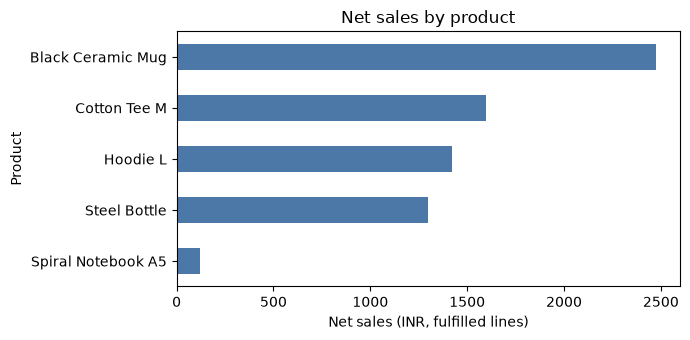

In [47]:
try:
    import matplotlib.pyplot as plt
    d = a1_product[a1_product.Currency == "INR"].sort_values("Net")
    ax = d.plot.barh(x="Product", y="Net", legend=False, figsize=(7, 3.5), color="#4C78A8")
    ax.set_xlabel("Net sales (INR, fulfilled lines)"); ax.set_title("Net sales by product"); plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed - chart skipped")

## 7. Exports
The privacy-safe analyst extract **requires a secret** (`export PII_TOKEN_KEY=...`, 16+ characters). Without one it is skipped, never silently tokenised with a default key.

In [48]:
def _prep(df):
    d = df.copy()
    if "Flags" in d.columns: d["Flags"] = d["Flags"].map(lambda fl: "; ".join(sorted({c for c, _ in fl})))
    return d
exports = {"cleaned_dataset.csv": _prep(res.clean), "review_quarantine_dataset.csv": _prep(res.review), "standardized_all_rows.csv": _prep(res.standardized),
           "superseded_duplicates.csv": _prep(res.superseded), "exceptions.csv": res.exceptions, "audit_log.csv": res.audit,
           "returns_clean.csv": returns_clean, "returns_exceptions.csv": returns_exceptions, "test_results.csv": test_results,
           "data_quality_report.csv": dq.astype({"Result": str}), "analysis_daily_net_sales.csv": a1_daily, "analysis_product_ranking.csv": a1_product,
           "analysis_aov.csv": a2, "analysis_returns_by_sku.csv": a3}
try:
    exports["analyst_extract_privacy_safe.csv"] = analyst_extract(res.clean)
except MissingTokenKeyError as e:
    print("analyst extract skipped:", e)
for name, d in exports.items(): d.to_csv(os.path.join(OUTPUT_DIR, name), index=False)
print(f"written to ./{OUTPUT_DIR}/:"); [print("  ", n, f"({len(d)} rows)") for n, d in exports.items()];

analyst extract skipped: no PII token key: set PII_TOKEN_KEY (>=16 chars), pass key=..., or opt in to a random key with PII_ALLOW_EPHEMERAL_KEY=1
written to ./K:\retail-pipeline\output/:
   cleaned_dataset.csv (12 rows)
   review_quarantine_dataset.csv (3 rows)
   standardized_all_rows.csv (18 rows)
   superseded_duplicates.csv (3 rows)
   exceptions.csv (9 rows)
   audit_log.csv (67 rows)
   returns_clean.csv (4 rows)
   returns_exceptions.csv (3 rows)
   test_results.csv (49 rows)
   data_quality_report.csv (34 rows)
   analysis_daily_net_sales.csv (7 rows)
   analysis_product_ranking.csv (6 rows)
   analysis_aov.csv (2 rows)
   analysis_returns_by_sku.csv (6 rows)


## 8. Testing on real datasets
The adapters in `retail_pipeline/adapters.py` map **Olist** (Kaggle `olistbr/brazilian-ecommerce`) and **UCI Online Retail II** (UCI 502; mirrored on Kaggle) onto the raw schema, declaring every assumption in their docstrings. Put the files next to the notebook and run the cell (or `python run_real_data_test.py --olist DIR --retail2 FILE`). Results from the verification run are in `REAL_DATA_RESULTS.md`.

In [49]:
RETAIL2_CSV, OLIST_DIR = str(REPO_ROOT / "data/online_retail_II.csv"), str(REPO_ROOT / "data/olist")
if os.path.exists(RETAIL2_CSV) or os.path.isdir(OLIST_DIR):
    import json, run_real_data_test as rt   # scripts/run_real_data_test.py
    if os.path.isdir(OLIST_DIR): print(json.dumps(rt.run_olist(OLIST_DIR, str(REPO_ROOT / "real_data_results"))[0], indent=1, default=str))
    if os.path.exists(RETAIL2_CSV): print(json.dumps(rt.run_online_retail(RETAIL2_CSV, str(REPO_ROOT / "real_data_results"))[0], indent=1, default=str))
else:
    print("Real datasets not found - see section 20 text for download locations.")

{
 "dataset": "Olist Brazilian E-Commerce (Kaggle olistbr/brazilian-ecommerce)",
 "adapter_s": 1.3,
 "order_item_lines": 112650,
 "orders": 98666,
 "pipeline_s": 10.5,
 "rows_per_s": 10711,
 "peak_mem_mb": 1049.2,
 "disposition": {
  "CLEAN": 112632,
  "REVIEW": 18
 },
 "ts_status": {
  "OK_ASSUMED_TZ": 112632,
  "AMBIGUOUS_DST": 18
 },
 "top_flags": "{('BLOCKING', 'TS_DST_AMBIGUOUS'): 18, ('WARNING', 'TS_TZ_ASSUMED'): 1}",
 "revenue_class": {
  "FULFILLED": 110197,
  "IN_PIPELINE": 1904,
  "EXCLUDED": 549
 },
 "payments": 103886,
 "payment_flags": {
  "PAYMENT_UNMATCHED_ORDER": 830,
  "PAYMENT_ZERO_AMOUNT": 9,
  "PAYMENT_METHOD_UNMAPPED": 3
 },
 "payment_methods": {
  "CARD": 78324,
  "BANK_SLIP": 19784,
  "VOUCHER": 5775,
  "UNMAPPED": 3
 },
 "payment_recon": {
  "MATCH": 98077,
  "PAID_MORE": 367,
  "PAID_LESS": 210
 },
 "shipments": 99441,
 "shipment_eligible": 98477,
 "shipment_flags": {
  "SHIPMENT_UNMATCHED_ORDER": 775,
  "SHIPPED_BEFORE_ORDERED": 166,
  "DELIVERED_BEFORE_SHIPPE

## 9. Scenario coverage and remaining limitations

| # | Cleaning scenario | Status |
|---|---|---|
| 1 | IDs, alias to master | implemented; ID rules and customer normalisers are configurable per source |
| 2 | Timestamps to UTC | implemented; explicit offset, declared IANA zone (DST-safe), declared/inferred date order; gaps and folds quarantined |
| 3 | Canonical product / SKU / category / brand | implemented against any `RefData`; derived references are labelled |
| 4 | Units to base unit | implemented (each / dozen / pack) |
| 5 | Numeric amounts | implemented in exact integer minor units; shipping and tax columns optional; precision loss flagged |
| 6 | Currency + daily FX | implemented; `load_fx_rates`, `fx_coverage`; any currency with 2 decimals |
| 7 | Country, channel, **state, postal code** | implemented (state tables for US/IN/BR; postal patterns for IN/US/BR/GB; extend `_STATES` / `_POSTAL`) |
| 8 | Duplicate detection | implemented; exact repeated rows without a source line id are *reported*, not dropped |
| 9 | Range validation | implemented (ceilings are per-`RefData` parameters) |
| 10 | Payment method / status | implemented (`clean_payments`, `reconcile_payments`) |
| 11 | Customer master matching | implemented |
| 12 | Promotion codes | implemented (applied / expired / rejected / unknown / unverifiable) |
| 13 | Return reasons and linkage | implemented, cumulative quantity and refund checks |
| 14 | Shipment tracking / carrier / status | implemented (`clean_shipments`) |
| 15 | Email / phone masking | implemented; tokenisation fails closed without a secret |
| 16 | Spikes, failed payments, refund ratios | implemented (`robust_anomalies`, `order_spikes`, repeated failed payments, `refund_ratio_flags`) |
| 17 | Reference-key validation | implemented (checked when a `RefData` is built and in the DQ report) |
| 18 | Cancelled / test / fraud separation | implemented (`Revenue_Class`) |
| 19 | Missing-value rules | implemented (unknown stays NULL; absent discount field is an explicit declared policy) |
| 20 | Out-of-order / late events | implemented (`reconcile_events`: lifecycle order beats arrival order; contradictions and late arrivals flagged) |

**Transformations available:** net sales by period/channel/currency (#1, #14), AOV and items per order (#2), cohorts and repeat rate (#3), conversion funnel (#4, needs event data), promotion redemption and discount cost (#5), product ranking (#6), returns (#7), lead time and on-time delivery by carrier (#8), payment authorisation / capture / failure (#10), historical CLV (#11), regional summary (#12), anomalies (#13), privacy-safe extract (#15). Inventory sell-through (#9) and device/acquisition comparison (#16) need inventory snapshots and session attributes that none of the tested datasets carry.

**Limitations that remain (by design or by data)**
* Reference tables in `demo_reference()` are still illustrative; real runs must supply a `RefData` (derived references are labelled and cannot detect unknown keys).
* Declared assumptions (source time zone, currency, discount policy) are the caller's responsibility; the pipeline records and reports them but cannot verify them.
* Currencies with other than 2 decimal places (JPY, KWD) are not supported.
* Credit notes without a reference to the original invoice (Online Retail II) can never be linked; the pipeline reports them as unmatched instead of guessing.
* Incremental promotion sales and predictive CLV need holdouts / models beyond cleaning; only descriptive versions are provided.
* The tracking-ID patterns and state/postal tables are configurable defaults; verify against current carrier and national standards.